Name: Md. Murad Hasan

ID: 23-55559-3

Section: E

Course: Computer Vision and Pattern Recognition

Dataset: Dry Fruits Image — Kaggle (CC BY 4.0)
  https://www.kaggle.com/datasets/warcoder/dry-fruits-image

  GitHub Repository link: https://github.com/mhtamim136/CVPR-Mid-Assignment


In [1]:
from torchvision import datasets
import torchvision.transforms as transforms

from torch.utils.data import Dataset, DataLoader

import torch
import torch.nn as nn

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
device = "cuda" if torch.cuda.is_available() else "cpu"
print(device)

cuda


In [2]:
import kagglehub
path = kagglehub.dataset_download("warcoder/dry-fruits-image")
print("Path to dataset files:", path)

100%|██████████| 328M/328M [00:02<00:00, 163MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/warcoder/dry-fruits-image/versions/1


In [3]:
import os
import torchvision.transforms as transforms
from torch.utils.data import random_split, Subset

size = 32

train_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor()
])

val_transform = transforms.Compose([
    transforms.Resize((size, size)),
    transforms.ToTensor()
])

# Find the main dataset folder.
CLASSES = ["ALMOND", "CASHEW", "FIG", "RAISIN"]

def find_root(base):
    for dirpath, dirnames, _ in os.walk(base):
        if set(CLASSES).issubset(set(dirnames)):
            return dirpath
    return None

ROOT = find_root(path)
print("Dataset root:", ROOT)

# Map the 12 subfolders to 4 classes.
leaf_names = datasets.ImageFolder(ROOT).classes
leaf_to_parent = [CLASSES.index(name.split("_")[0]) for name in leaf_names]

train_full = datasets.ImageFolder(ROOT, transform=train_transform,
                                  target_transform=lambda i: leaf_to_parent[i])
val_full = datasets.ImageFolder(ROOT, transform=val_transform,
                                target_transform=lambda i: leaf_to_parent[i])

# Drop 2 duplicate images.
DUPLICATES = {"ALMOND_REGULAR_490.jpg", "RAISIN_BLACK_181.jpg"}
keep = [i for i, (p, _) in enumerate(train_full.samples)
        if os.path.basename(p) not in DUPLICATES]
print(f"images after dropping duplicates: {len(keep)} (of {len(train_full)})")

# Random 80/10/10 split, seed 42.
g = torch.Generator().manual_seed(42)
perm = torch.randperm(len(keep), generator=g).tolist()
shuffled = [keep[i] for i in perm]
n_train = int(0.8 * len(shuffled))
n_val = int(0.1 * len(shuffled))
train_idx = shuffled[:n_train]
val_idx = shuffled[n_train:n_train + n_val]
test_idx = shuffled[n_train + n_val:]

train_data = Subset(train_full, train_idx)
val_data = Subset(val_full, val_idx)
test_data = Subset(val_full, test_idx)

Dataset root: /root/.cache/kagglehub/datasets/warcoder/dry-fruits-image/versions/1/Dry Fruit Image Dataset/DRY FRUIT IMAGE DATASET
images after dropping duplicates: 11518 (of 11520)


In [4]:
print('Dataset Summary')
print('Train Data: ', len(train_data))
print('Validation Data: ', len(val_data))
print('Test Data: ', len(test_data))
print('Classes and Indices: ', {c: i for i, c in enumerate(CLASSES)})

Dataset Summary
Train Data:  9214
Validation Data:  1151
Test Data:  1153
Classes and Indices:  {'ALMOND': 0, 'CASHEW': 1, 'FIG': 2, 'RAISIN': 3}


In [5]:
batch_size = 32
learning_rate=1e-3
epoch_number = 10

In [6]:
trn_dl = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=2)
val_dl = DataLoader(val_data, batch_size=batch_size, shuffle=False, num_workers=2)
test_dl = DataLoader(test_data, batch_size=batch_size, shuffle=False, num_workers=2)

In [7]:
from torch.optim import SGD, Adam
def get_model():

    model = nn.Sequential(
        #Feature Extraction
        nn.Conv2d(3, 64, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),
        nn.Conv2d(64, 128, kernel_size=3),
        nn.ReLU(),
        nn.MaxPool2d(2),

        #Classifier
        nn.Flatten(),
        nn.Linear(128*6*6, 256),
        nn.ReLU(),
        nn.Linear(256, 4)
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()
    optimizer = Adam(model.parameters(), lr=learning_rate)
    return model, loss_fn, optimizer

In [8]:
def train_one_epoch(data_loader, model, loss_fn, optimizer):
    model.train()
    epoch_losses, epoch_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)

        optimizer.zero_grad()
        prediction = model(x)
        batch_loss = loss_fn(prediction, y)
        batch_loss.backward()
        optimizer.step()

        epoch_losses.append(batch_loss.item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        epoch_accuracies.extend(is_correct)
    return np.mean(epoch_losses), np.mean(epoch_accuracies)

@torch.no_grad()
def validation(data_loader, model, loss_fn):
    model.eval()
    val_losses, val_accuracies = [], []
    for x, y in data_loader:
        x, y = x.to(device), y.to(device)   # move to device here
        prediction = model(x)
        val_losses.append(loss_fn(prediction, y).item())
        is_correct = (prediction.argmax(-1) == y).tolist()
        val_accuracies.extend(is_correct)
    return np.mean(val_losses), np.mean(val_accuracies)

In [9]:
from torchsummary import summary
model, loss_fn, optimizer = get_model()
summary(model, input_size=(3,32,32));

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
           Flatten-7                 [-1, 4608]               0
            Linear-8                  [-1, 256]       1,179,904
              ReLU-9                  [-1, 256]               0
           Linear-10                    [-1, 4]           1,028
Total params: 1,256,580
Trainable params: 1,256,580
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 1.39
Params size (MB): 4.79
Estimat

In [10]:
## Training Loop
train_losses, train_accuracies = [], []
val_losses, val_accuracies = [], []

for epoch in range(epoch_number):
  epoch_loss, epoch_accuracy = train_one_epoch(trn_dl,model,loss_fn,optimizer)
  train_losses.append(epoch_loss)
  train_accuracies.append(epoch_accuracy)

  v_loss, v_acc =  validation(val_dl,model,loss_fn)
  val_losses.append(v_loss)
  val_accuracies.append(v_acc)

  print(f"Epoch [{epoch + 1}/{epoch_number}]"
        f" | Train Loss: {epoch_loss:.4f} | Train Accuracy: {epoch_accuracy*100:.2f}%"
        f" | Val Loss: {v_loss:.4f} | Val Accuracy: {v_acc*100:.2f}%")

Epoch [1/10] | Train Loss: 0.8378 | Train Accuracy: 64.49% | Val Loss: 0.5786 | Val Accuracy: 75.76%
Epoch [2/10] | Train Loss: 0.4506 | Train Accuracy: 83.10% | Val Loss: 0.3461 | Val Accuracy: 87.05%
Epoch [3/10] | Train Loss: 0.3046 | Train Accuracy: 88.86% | Val Loss: 0.2125 | Val Accuracy: 92.62%
Epoch [4/10] | Train Loss: 0.2253 | Train Accuracy: 91.90% | Val Loss: 0.1434 | Val Accuracy: 94.79%
Epoch [5/10] | Train Loss: 0.1699 | Train Accuracy: 94.00% | Val Loss: 0.1689 | Val Accuracy: 93.14%
Epoch [6/10] | Train Loss: 0.1407 | Train Accuracy: 94.98% | Val Loss: 0.0933 | Val Accuracy: 97.05%
Epoch [7/10] | Train Loss: 0.1270 | Train Accuracy: 95.69% | Val Loss: 0.1373 | Val Accuracy: 94.96%
Epoch [8/10] | Train Loss: 0.1007 | Train Accuracy: 96.68% | Val Loss: 0.0641 | Val Accuracy: 97.65%
Epoch [9/10] | Train Loss: 0.0831 | Train Accuracy: 97.06% | Val Loss: 0.0727 | Val Accuracy: 97.22%
Epoch [10/10] | Train Loss: 0.0857 | Train Accuracy: 96.86% | Val Loss: 0.0585 | Val Accura

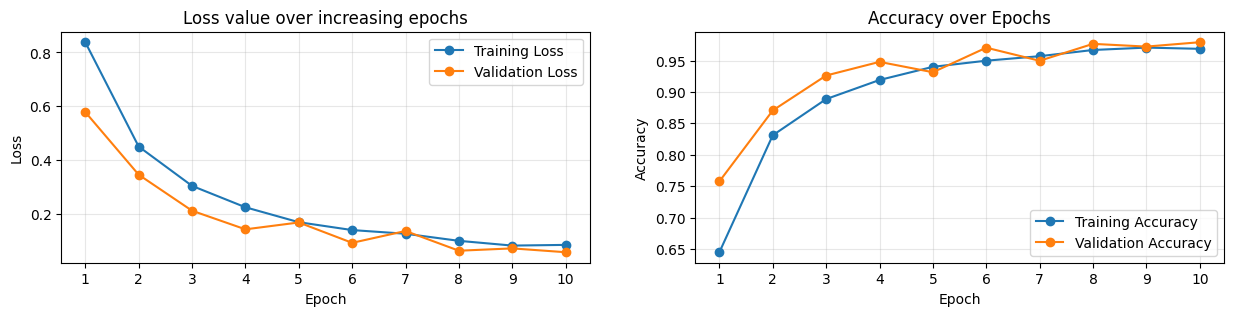

In [11]:
# Plot loss and accuracy curves
epochs = np.arange(epoch_number) + 1
plt.figure(figsize=(15, 3))
plt.subplot(121)
plt.title("Loss value over increasing epochs")
plt.plot(epochs, train_losses, marker='o', label="Training Loss")
plt.plot(epochs, val_losses, marker='o', label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)

plt.subplot(122)
plt.title("Accuracy over Epochs")
plt.plot(epochs, train_accuracies, marker='o', label="Training Accuracy")
plt.plot(epochs, val_accuracies, marker='o', label="Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(alpha=0.3)
plt.show()

Test Loss: 0.0513 | Test Accuracy: 98.53%
per-class accuracy: {'ALMOND': np.float64(0.9899), 'CASHEW': np.float64(0.9964), 'FIG': np.float64(0.9685), 'RAISIN': np.float64(0.9863)}
confusion matrix (rows=true, cols=pred; order ALMOND, CASHEW, FIG, RAISIN):
[[294   0   1   2]
 [  0 278   0   1]
 [  1   2 277   6]
 [  1   0   3 287]]


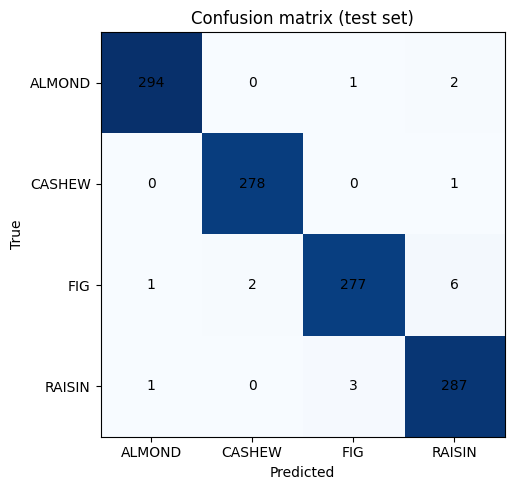

In [12]:
from sklearn.metrics import confusion_matrix

test_loss, test_acc = validation(test_dl, model, loss_fn)
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc*100:.2f}%")

# Per-class accuracy and confusion matrix.
model.eval()
all_pred, all_true = [], []
with torch.no_grad():
    for x, y in test_dl:
        x, y = x.to(device), y.to(device)
        all_pred += model(x).argmax(1).tolist()
        all_true += y.tolist()

cm = confusion_matrix(all_true, all_pred)
per_class = {c: round(cm[i][i] / max(1, cm[i].sum()), 4) for i, c in enumerate(CLASSES)}
print("per-class accuracy:", per_class)
print("confusion matrix (rows=true, cols=pred; order ALMOND, CASHEW, FIG, RAISIN):")
print(cm)

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.xticks(range(4), CLASSES); plt.yticks(range(4), CLASSES)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (test set)")
for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha="center", va="center")
plt.tight_layout()
plt.show()

In [13]:
# Save the trained weights
torch.save(model.state_dict(), 'CNN_23-55559-3.pth')
print(f"saved CNN_23-55559-3.pth ({os.path.getsize('CNN_23-55559-3.pth')/1e6:.1f} MB)")

saved CNN_23-55559-3.pth (5.0 MB)


In [14]:
saved_model = get_model()[0]
saved_model.load_state_dict(torch.load('CNN_23-55559-3.pth'))
saved_model.eval()
summary(saved_model, input_size=(3,32,32))

# Check the loaded model gives the same accuracy.
reload_loss, reload_acc = validation(test_dl, saved_model, loss_fn)
print(f"Reloaded model — Test Loss: {reload_loss:.4f} | Test Accuracy: {reload_acc*100:.2f}%")

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1           [-1, 64, 30, 30]           1,792
              ReLU-2           [-1, 64, 30, 30]               0
         MaxPool2d-3           [-1, 64, 15, 15]               0
            Conv2d-4          [-1, 128, 13, 13]          73,856
              ReLU-5          [-1, 128, 13, 13]               0
         MaxPool2d-6            [-1, 128, 6, 6]               0
           Flatten-7                 [-1, 4608]               0
            Linear-8                  [-1, 256]       1,179,904
              ReLU-9                  [-1, 256]               0
           Linear-10                    [-1, 4]           1,028
Total params: 1,256,580
Trainable params: 1,256,580
Non-trainable params: 0
----------------------------------------------------------------
Input size (MB): 0.01
Forward/backward pass size (MB): 1.39
Params size (MB): 4.79
Estimat

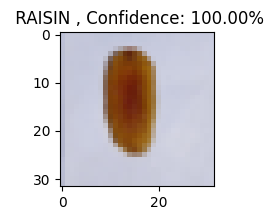

In [15]:
# Show one test image with the prediction
test_img, label = test_data[2]
img = test_img.view(-1,3,size,size).to(device)

output = model(img)
pred = torch.exp(output)/torch.sum(torch.exp(output))
confidence, index  = pred.max(-1)

plt.figure(figsize=(2,2))
plt.imshow(test_img.view(3,size,size).permute(1,2,0))
plt.title(f' {CLASSES[index]} , Confidence: {confidence.item()*100:0.2f}%')
plt.show()

## Analysis & Discussion of Results

- Test accuracy 98.53% (loss 0.0513) on 1,153 test images; validation 97.91%, train 96.86% at epoch 10.
- Per-class accuracy: CASHEW 99.64%, ALMOND 98.99%, RAISIN 98.63%, FIG 96.85%. FIG is the weakest — 6 of its 9 errors were predicted as RAISIN (the two look most alike).
- 17 of 1,153 test images were wrong. The confusion matrix shows most errors are between FIG and RAISIN.
- Validation crossed 90% at epoch 3 and flattened after epoch 8, so 10 epochs were enough; training longer would add little.
- Hyperparameters: batch size 32, Adam with lr 1e-3, 10 epochs — the standard values from the course pipeline. 10 epochs were enough because validation flattened after epoch 8.
- No overfitting: train (96.86%) and validation (97.91%) are close, and validation is even slightly higher because augmentation is applied to training images only.
- Limitation: the dataset has several photos of the same nut from different angles, and the file names do not say which nut is which, so the same nut may appear in both train and test. The test accuracy may therefore be slightly optimistic.

## Conclusions & Future Work

- A simple 2-block CNN trained from scratch reached 98.53% test accuracy on 4 dry-fruit classes.
- Future work: try a larger input size, and a nut-aware split if nut identity were known; add more fruit classes.